# Part 1: Practise

## Task 1 : Set up, and the first histogram

### Import libraries, set them as whitegrid

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### load the table with parse dates

In [2]:
date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_columns)
print(listings.shape)

(4574, 73)


### way 1 : Draw a histogram of number_of_reviews with pure matplotlib

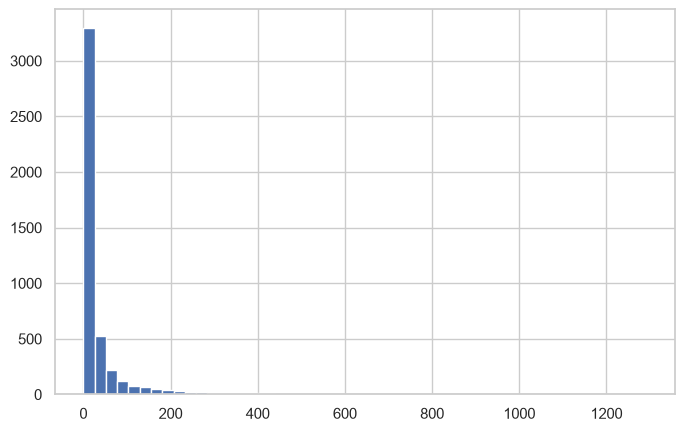

In [3]:
fig, ax = plt.subplots(figsize=(8,5))
ax.hist(listings["number_of_reviews"], bins=50)
plt.show()

### way 2 : Draw the same histogram of number_of_reviews with seaborn

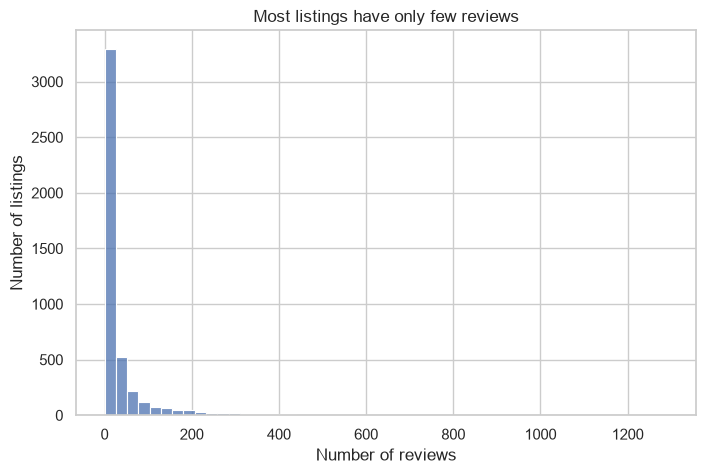

In [4]:
fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)

ax.set_title("Most listings have only few reviews")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")

plt.show()

### Extra: find the range and count of the first bar (ax.patches)

`ax.patches[0]` is the first bar of the histogram.

- get_x() = where it starts, 
- get_width() = how wide, 
- get_height() = how many listings.

**Result:** the first bar goes from 0 to 25.86 reviews and holds 3297 listings (72 % of 4574).

So 3297 listings has 0 to 25.86 reviews

starts at: 0.0
width:     25.86
ends at:   25.86
height:    3297


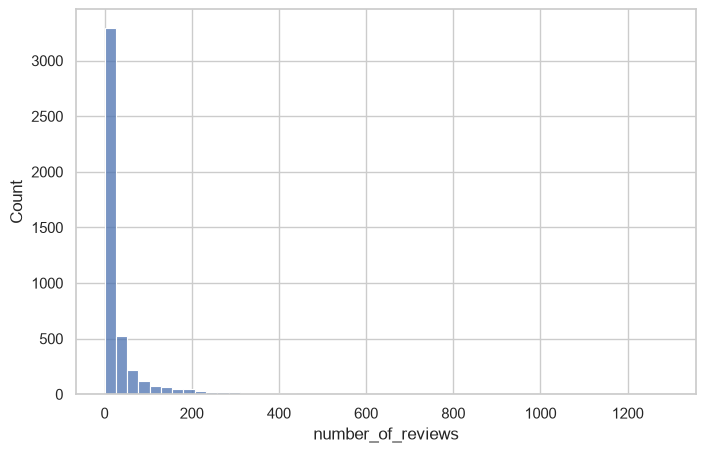

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)

first = ax.patches[0]
print("starts at:", first.get_x())
print("width:    ", first.get_width())
print("ends at:  ", first.get_x() + first.get_width())
print("height:   ", first.get_height())   # how many listings

plt.show()

### Task 1: What I learned

**A histogram** puts the listings into buckets by number of reviews and counts them.
Each bar = one bucket. Taller bar = more listings in that bucket.

**What the chart shows:**
Most listings have only a few reviews (the tall bar on the left).
Only a few listings have many reviews (the low bars stretching to the right).

**matplotlib vs seaborn:**
- Both draw the same chart.
- matplotlib gives no title and no axis names.
- seaborn gives axis names by itself (the column name we mention in x and "Count"), but no title.
- In both, I add my own title and axis names the same way:
  `ax.set_title()`, `ax.set_xlabel()`, `ax.set_ylabel()`

## Task 2 : Mean, median and the fence

### calculate the mean, median and the upper fence

In [6]:
# use describe() for a quick overview with your eyes
# It shows all the summary numbers at once (count, mean, 25%, 50%, 75%, max...)

listings["number_of_reviews"].describe()

count    4574.000000
mean       35.754045
std        78.377200
min         0.000000
25%         2.000000
50%         9.000000
75%        29.000000
max      1293.000000
Name: number_of_reviews, dtype: float64

In [7]:
median = listings["number_of_reviews"].median()
mean = listings["number_of_reviews"].mean()

q1 = listings["number_of_reviews"].quantile(0.25)
q3 = listings["number_of_reviews"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

print(median, mean, upper)

9.0 35.75404459991255 69.5


### Draw the histogram with vertical line

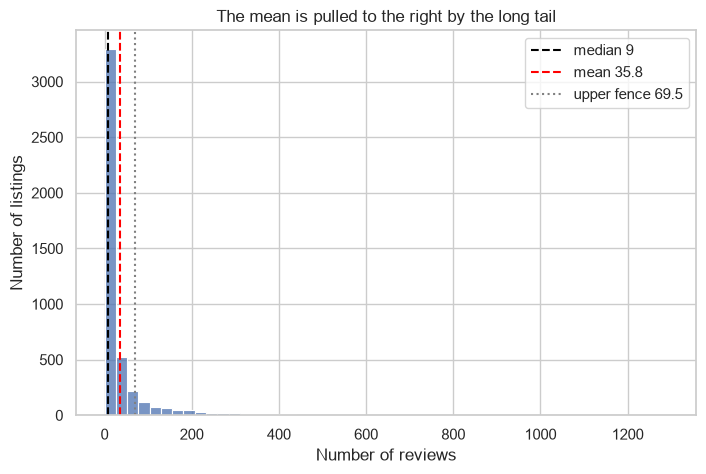

In [8]:
fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)

ax.axvline(median, color="black", linestyle="--", label=f"median {median:.0f}")
ax.axvline(mean,   color="red",   linestyle="--", label=f"mean {mean:.1f}")
ax.axvline(upper,  color="gray",  linestyle=":",  label=f"upper fence {upper:.1f}")

ax.set_title("The mean is pulled to the right by the long tail")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")

ax.legend()
plt.show()

- median        : 9 reviews    : the middle listing has 9 reviews
- mean          : 35.8 reviews : the average listing has 35.8 reviews
- upper fence   : 69.5 reviews : a listing with more than 69.5 reviews is an outlier

- The upper fence (69.5) is furthest to the right, because it is Q3 plus 1.5 × IQR: it is placed past the normal listings on purpose, to mark where the outliers start.
- The mean (35.8) is to the right of the median (9), because a few listings with very many reviews (up to 1293) pull the mean up. The median only looks at the middle listing, so it stays at 9.

## Task 3 : Hide the outliers

In [9]:
listings["reviews_outlier"] = listings["number_of_reviews"] > upper

listings["reviews_outlier"] holds :
 
- It holds one True or False for every listing: 4574 answers, one per row.
- Each row answers the question: "Does this listing have more than 69.5 reviews?"
- True = weird listing (an outlier, more than 69.5 reviews): 582 rows
- False = normal listing (69 or fewer): 3992 rows


### How many listings are outliers (past the upper fence)

In [10]:
print(listings["reviews_outlier"].sum())

582


### How many listings are normal (not outliers)

In [11]:
print((~listings["reviews_outlier"]).sum())

3992


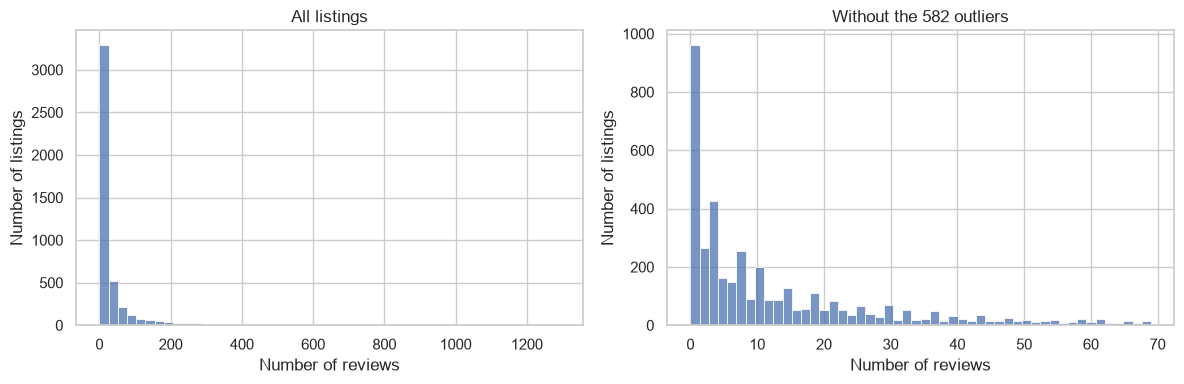

In [12]:
n_out = listings["reviews_outlier"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=axes[0])
sns.histplot(data=listings[~listings["reviews_outlier"]], x="number_of_reviews", bins=50, ax=axes[1])

axes[0].set_title("All listings")
axes[1].set_title(f"Without the {n_out} outliers")

for ax in axes:
    ax.set_xlabel("Number of reviews")
    ax.set_ylabel("Number of listings")

plt.tight_layout()
plt.show()


- The left chart has all the listings including the 582 outliers. 
- So they stretch the x-axis all the way to 1293 reviews, so almost all the normal listings are squeezed into one tall bar and we can't see how they are spread.

- In the right chart we removed the outliers, so the range is only 0 to 70 reviews and the same listings are split into many thin bars. 
- Now we can see that most listings have fewer than 10 reviews. 
- The tallest bar is at 0 to 1 reviews, with about 950 listings, and the bars get smaller and smaller as the number of reviews goes up.


So a typical Stockholm listing has only a few reviews. The listings with hundreds of reviews are rare.

## Task 4 : The boxplot

### Step 1: keep only the two room types, with isin

In [13]:
two_types = listings[listings["room_type"].isin(["Entire home/apt", "Private room"])]
print(len(two_types))

4547


In [14]:
print(two_types.shape)

(4547, 74)


### Step 2: count the listings above 300 reviews

In [15]:
n_300 = (two_types["number_of_reviews"] > 300).sum()
print(n_300)

90


90 listings (out of the 4547 in the two room types) have more than 300 reviews.

### Draw the boxplot

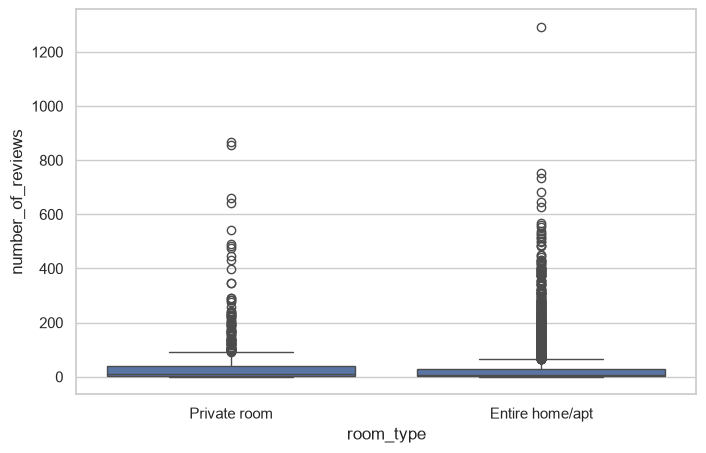

In [16]:
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=two_types, x="room_type", y="number_of_reviews", ax=ax)

plt.show()

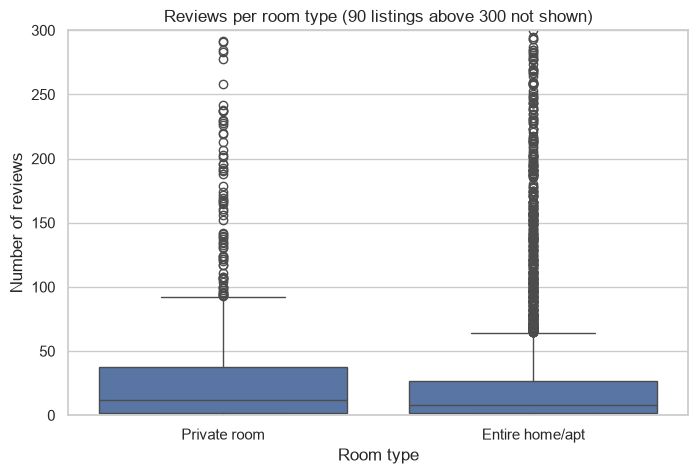

In [17]:
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=two_types, x="room_type", y="number_of_reviews", ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f"Reviews per room type ({n_300} listings above 300 not shown)")
ax.set_xlabel("Room type")
ax.set_ylabel("Number of reviews")

plt.show()

### Which room type has the higher median

In [18]:
two_types.groupby("room_type")["number_of_reviews"].median()

room_type
Entire home/apt     8.0
Private room       12.0
Name: number_of_reviews, dtype: float64

- Private room has the higher median: 12 reviews, against 8 for Entire home/apt.
- So a typical private room gets a few more reviews than a typical whole flat.

## Task 5 : The bar charts

In [ ]:
order = listings["room_type"].value_counts().index

In [24]:
print(order)

Index(['Entire home/apt', 'Private room', 'Shared room', 'Hotel room'], dtype='str', name='room_type')


value_counts() gives you two things: the names and the counts.

```
Entire home/apt    3760   ← count
Private room        787
Shared room          24
Hotel room            3
↑ names = the index
```


.index keeps just the names
['Entire home/apt', 'Private room', 'Shared room', 'Hotel room']

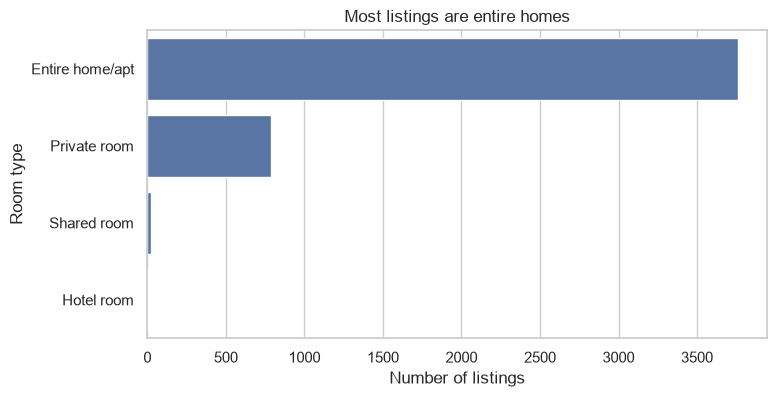

In [20]:
fig, ax = plt.subplots(figsize=(8,4))
sns.countplot(data=listings, y="room_type", order=order, ax=ax)
ax.set_title("Most listings are entire homes")
ax.set_xlabel("Number of listings")
ax.set_ylabel("Room type")
plt.show()

In [22]:
table = listings.groupby("neighbourhood_cleansed")["number_of_reviews"].agg(["median", "count"])
print(table)

                        median  count
neighbourhood_cleansed               
Bromma                     5.0    281
Enskede-Årsta-Vantörs      7.0    445
Farsta                     4.0    177
Hägersten-Liljeholmens     8.0    464
Hässelby-Vällingby         4.0    148
Kungsholmens              12.0    420
Norrmalms                 10.0    469
Rinkeby-Tensta             5.0    108
Skarpnäcks                 8.0    221
Skärholmens                3.0     96
Spånga-Tensta              7.0     89
Södermalms                17.0   1145
Älvsjö                     8.5    214
Östermalms                 9.0    297


groupby makes the groups, and .agg(["median", "count"]) makes the two columns.

In [23]:
table = table.sort_values("median", ascending=False)
table["label"] = table.index + " (" + table["count"].astype(str) + ")"
print(table)

                        median  count                         label
neighbourhood_cleansed                                             
Södermalms                17.0   1145             Södermalms (1145)
Kungsholmens              12.0    420            Kungsholmens (420)
Norrmalms                 10.0    469               Norrmalms (469)
Östermalms                 9.0    297              Östermalms (297)
Älvsjö                     8.5    214                  Älvsjö (214)
Hägersten-Liljeholmens     8.0    464  Hägersten-Liljeholmens (464)
Skarpnäcks                 8.0    221              Skarpnäcks (221)
Spånga-Tensta              7.0     89            Spånga-Tensta (89)
Enskede-Årsta-Vantörs      7.0    445   Enskede-Årsta-Vantörs (445)
Bromma                     5.0    281                  Bromma (281)
Rinkeby-Tensta             5.0    108          Rinkeby-Tensta (108)
Farsta                     4.0    177                  Farsta (177)
Hässelby-Vällingby         4.0    148      Hässe

sort_values("median", ascending=False) => sorts by the median column

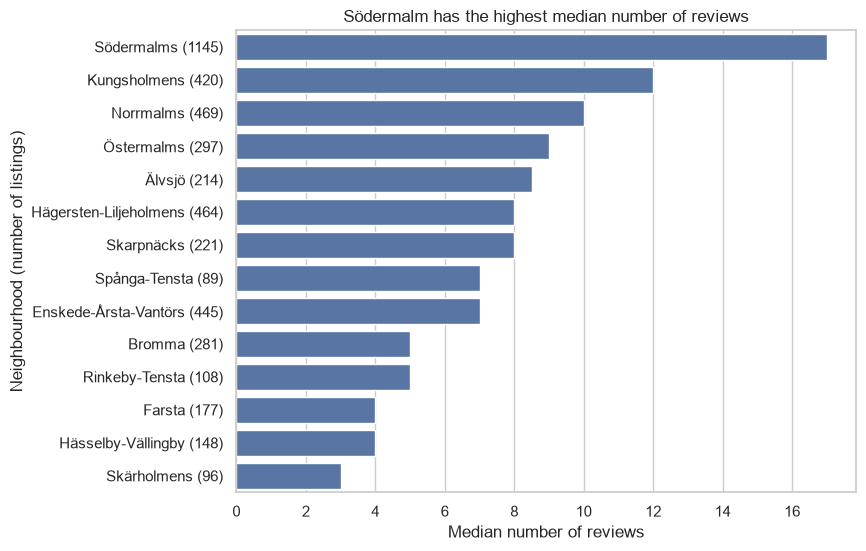

In [25]:
fig, ax = plt.subplots(figsize=(8,6))
sns.barplot(data=table, x="median", y="label", ax=ax)
ax.set_title("Södermalm has the highest median number of reviews")
ax.set_xlabel("Median number of reviews")
ax.set_ylabel("Neighbourhood (number of listings)")
plt.show()

- The highest median is Södermalms: 17 reviews.
- The most listings is also Södermalms: 1145 listings.
- The lowest median is Skärholmens: 3 reviews (96 listings).

## Task 6 : The scatter plot

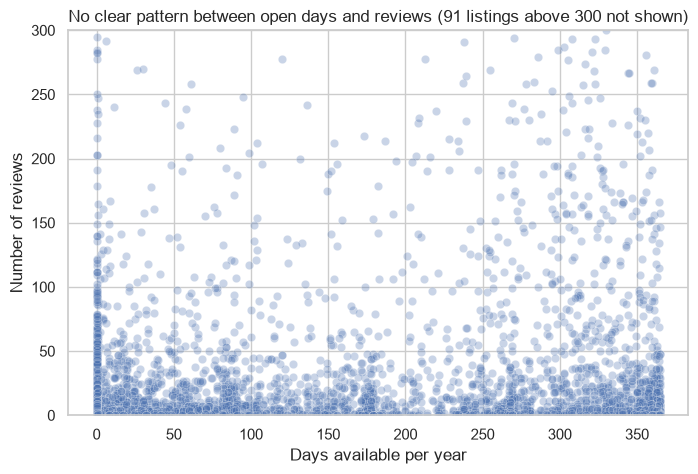

In [26]:
n_out6 = (listings["number_of_reviews"] > 300).sum()

fig, ax = plt.subplots(figsize=(8,5))
sns.scatterplot(data=listings, x="availability_365", y="number_of_reviews", alpha=0.3, ax=ax)
ax.set_ylim(0, 300)
ax.set_title(f"No clear pattern between open days and reviews ({n_out6} listings above 300 not shown)")
ax.set_xlabel("Days available per year")
ax.set_ylabel("Number of reviews")
plt.show()

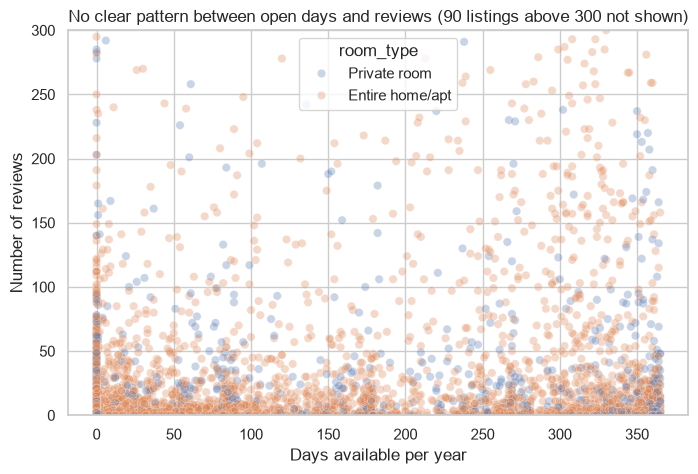

In [29]:
n_out6 = (listings["number_of_reviews"] > 300).sum()

fig, ax = plt.subplots(figsize=(8,5))
sns.scatterplot(data=two_types, x="availability_365", y="number_of_reviews", alpha=0.3, hue="room_type", ax=ax)
ax.set_ylim(0, 300)
ax.set_title(f"No clear pattern between open days and reviews ({n_300} listings above 300 not shown)")
ax.set_xlabel("Days available per year")
ax.set_ylabel("Number of reviews")
plt.show()

- No clear line or slope: a cloud of dots, thickest at the bottom (few reviews), spread over the whole x-axis from 0 to 365 days.
- So being open more days does not clearly mean more reviews. The pattern is weak, which matches the correlation of 0.18 (close to 0 = weak).
- In the second chart, the two room types overlap a lot, so room type does not change the pattern.

## Task 7

In [32]:
cols = ["number_of_reviews", "price", "accommodates", "bedrooms",
        "availability_365", "review_scores_rating", "minimum_nights", "days_since_review"]
corr = listings[cols].corr()
print(corr)

                      number_of_reviews     price  accommodates  bedrooms  \
number_of_reviews              1.000000 -0.091789     -0.050848 -0.144178   
price                         -0.091789  1.000000      0.580770  0.584440   
accommodates                  -0.050848  0.580770      1.000000  0.775402   
bedrooms                      -0.144178  0.584440      0.775402  1.000000   
availability_365               0.183156 -0.004249     -0.009214 -0.072168   
review_scores_rating          -0.039295  0.169746      0.052964  0.126265   
minimum_nights                -0.065609 -0.092166     -0.075903 -0.051957   
days_since_review             -0.185301  0.009832     -0.064501 -0.023908   

                      availability_365  review_scores_rating  minimum_nights  \
number_of_reviews             0.183156             -0.039295       -0.065609   
price                        -0.004249              0.169746       -0.092166   
accommodates                 -0.009214              0.052964      

### What corr means

- `corr` is one table: 8 columns × 8 rows, with the same names on both sides 
- Row name meets column name = how strongly those two columns move together.
- Scale: 1 = perfect together, 0.5+ = strong, around 0 = no link, minus = one goes up while the other goes down.
- The diagonal is always 1.00 (a column with itself).

Examples from my table:
- accommodates & bedrooms = 0.78 → more guests, more bedrooms (strong).
- price & accommodates = 0.58 → more guests, higher price (medium).
- number_of_reviews & availability_365 = 0.18 → open more days, only a tiny bit more reviews (weak).
- number_of_reviews & days_since_review = -0.19 → longer since the last review, slightly fewer reviews (weak, opposite).

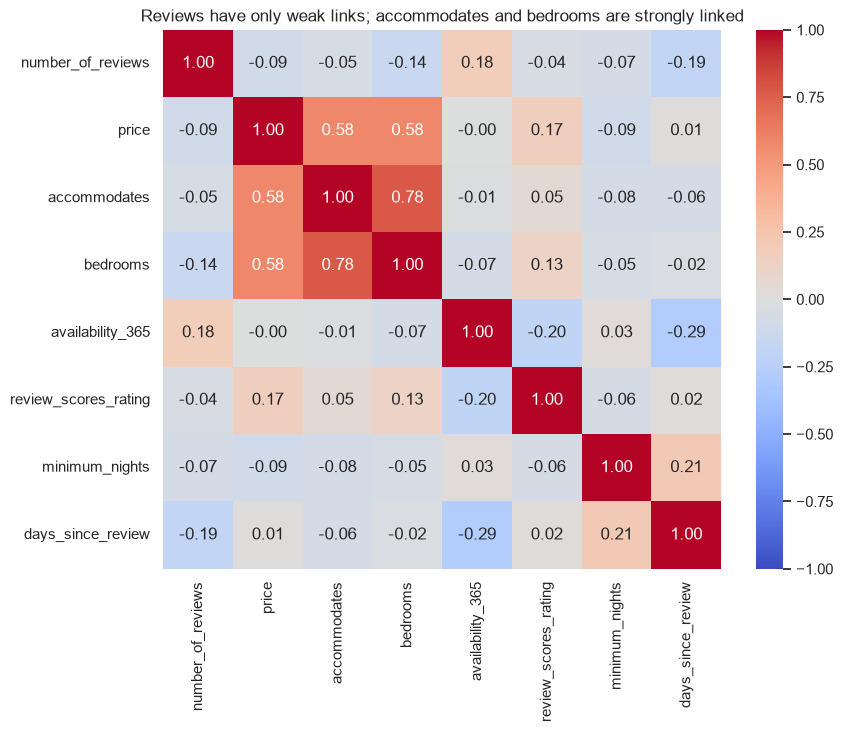

In [33]:
fig, ax = plt.subplots(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Reviews have only weak links; accommodates and bedrooms are strongly linked")
plt.show()

### What the heatmap lines do

- `sns.heatmap(corr, ...)` → draws the corr table as coloured squares.
  - `annot=True` → writes the number inside each square.
  - `fmt=".2f"` → shows 2 decimals (0.78 instead of 0.775402).
  - `cmap="coolwarm"` → red = positive, blue = negative, white = near 0.
  - `vmin=-1, vmax=1` → the colour scale goes from -1 to 1, so the colours are fair.


- The first row (number_of_reviews) has only pale squares: the strongest are availability_365 0.18 and days_since_review -0.19. So no column here really explains the number of reviews.
- The strong red squares are elsewhere: accommodates & bedrooms 0.78, and price with both 0.58 (bigger places cost more).
- The diagonal is 1.00 (each column with itself).

In [34]:
per_year = listings["last_review"].dt.year.value_counts().sort_index()
print(per_year)

last_review
2014.0       2
2015.0       7
2016.0       4
2017.0      15
2018.0      24
2019.0      58
2020.0      36
2021.0      55
2022.0     118
2023.0     198
2024.0     335
2025.0     373
2026.0    2705
Name: count, dtype: int64


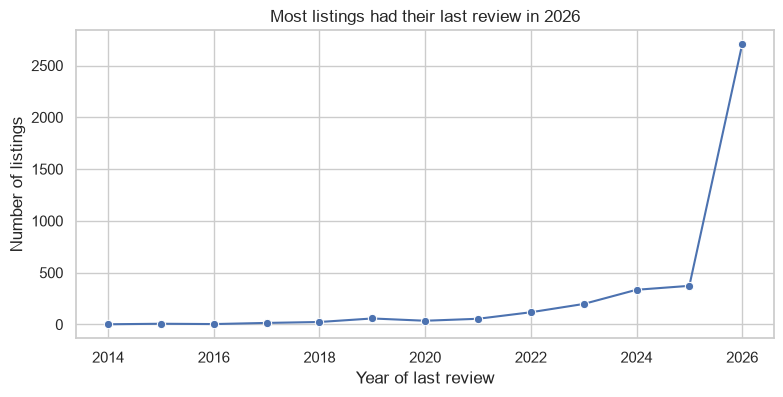

In [35]:
fig, ax = plt.subplots(figsize=(9,4))
sns.lineplot(x=per_year.index, y=per_year.values, marker="o", ax=ax)
ax.set_title("Most listings had their last review in 2026")
ax.set_xlabel("Year of last review")
ax.set_ylabel("Number of listings")
plt.show()

- .dt.year takes just the year from the date (2026-05-14 becomes 2026)
- value_counts() gives listings per year
- sort_index() sorts by year (not biggest first), because a line over time must go in time order
- .index = the years (x), and .values = the counts (y)
- marker="o" puts a dot on each year

- The line is nearly flat from 2014 to 2022, then rises, and 2026 is far higher: 2705 listings had their last review in 2026.
- So most listings are "active": guests still review them.
- 2026 is not a full year (the data ends in September), so it would be even higher.

## Task 8 : A Chart that lies, and a chart that does not

In [37]:
rating = two_types.groupby("room_type")["review_scores_rating"].agg(["median", "count"]).reset_index()
print(rating)

         room_type  median  count
0  Entire home/apt    4.92   3229
1     Private room    4.89    675


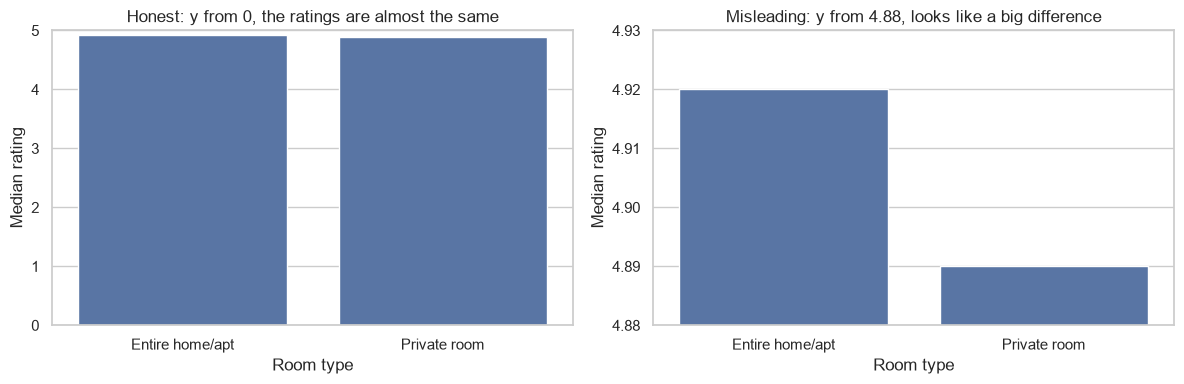

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax in axes:
    sns.barplot(data=rating, x="room_type", y="median", ax=ax)
    ax.set_xlabel("Room type")
    ax.set_ylabel("Median rating")

axes[0].set_ylim(0, 5)
axes[0].set_title("Honest: y from 0, the ratings are almost the same")
axes[1].set_ylim(4.88, 4.93)
axes[1].set_title("Misleading: y from 4.88, looks like a big difference")
plt.tight_layout()
plt.show()

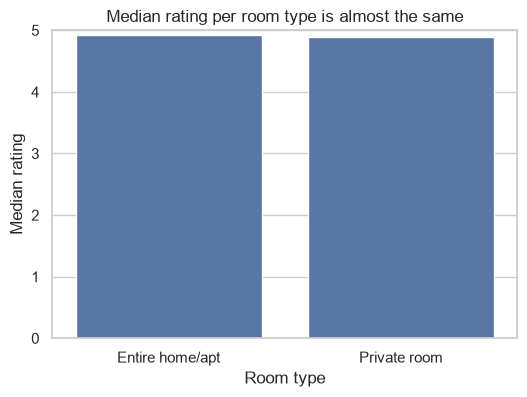

In [39]:
fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(data=rating, x="room_type", y="median", ax=ax)
ax.set_ylim(0, 5)
ax.set_title("Median rating per room type is almost the same")
ax.set_xlabel("Room type")
ax.set_ylabel("Median rating")
fig.savefig("rating_per_room_type.png", dpi=150, bbox_inches="tight")
plt.show()

- Medians: Entire home/apt 4.92 (3229 rated listings), Private room 4.89 (675).
- Left chart (y from 0): the two bars look the same, which is the truth.
- Right chart (y from 4.88): the entire home bar looks about 4 times as high (0.04 against 0.01). It makes me believe entire homes are rated much better.
- But the real difference is only 0.03 on a scale from 1 to 5. Cutting the y-axis makes a tiny difference look big.
- The honest chart is saved as rating_per_room_type.png.